In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
#uploading the dataset
df = pd.read_csv('heart_2022_no_nans.csv')

In [ ]:
# checking first five rows of the dataset
df.head()

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,...,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Alabama,Female,Very good,4.0,0.0,Within past year (anytime less than 12 months ...,Yes,9.0,None of them,No,...,1.60,71.67,27.99,No,No,Yes,Yes,"Yes, received Tdap",No,No
1,Alabama,Male,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,6.0,None of them,No,...,1.78,95.25,30.13,No,No,Yes,Yes,"Yes, received tetanus shot but not sure what type",No,No
2,Alabama,Male,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,No,8.0,"6 or more, but not all",No,...,1.85,108.86,31.66,Yes,No,No,Yes,"No, did not receive any tetanus shot in the pa...",No,Yes
3,Alabama,Female,Fair,5.0,0.0,Within past year (anytime less than 12 months ...,Yes,9.0,None of them,No,...,1.70,90.72,31.32,No,No,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,Yes
4,Alabama,Female,Good,3.0,15.0,Within past year (anytime less than 12 months ...,Yes,5.0,1 to 5,No,...,1.55,79.38,33.07,No,No,Yes,Yes,"No, did not receive any tetanus shot in the pa...",No,No


In [ ]:
# checking shape of the dataset
df.shape

(246022, 40)

In [ ]:
# checking information of teh dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246022 entries, 0 to 246021
Data columns (total 40 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   State                      246022 non-null  object 
 1   Sex                        246022 non-null  object 
 2   GeneralHealth              246022 non-null  object 
 3   PhysicalHealthDays         246022 non-null  float64
 4   MentalHealthDays           246022 non-null  float64
 5   LastCheckupTime            246022 non-null  object 
 6   PhysicalActivities         246022 non-null  object 
 7   SleepHours                 246022 non-null  float64
 8   RemovedTeeth               246022 non-null  object 
 9   HadHeartAttack             246022 non-null  object 
 10  HadAngina                  246022 non-null  object 
 11  HadStroke                  246022 non-null  object 
 12  HadAsthma                  246022 non-null  object 
 13  HadSkinCancer              24

In [ ]:
# descriptive statistics
df.describe()

,PhysicalHealthDays,MentalHealthDays,SleepHours,HeightInMeters,WeightInKilograms,BMI
count,246022.000000,246022.000000,246022.000000,246022.000000,246022.000000,246022.000000
mean,4.119026,4.167140,7.021331,1.705150,83.615179,28.668136
std,8.405844,8.102687,1.440681,0.106654,21.323156,6.513973
min,0.000000,0.000000,1.000000,0.910000,28.120000,12.020000
25%,0.000000,0.000000,6.000000,1.630000,68.040000,24.270000
50%,0.000000,0.000000,7.000000,1.700000,81.650000,27.460000
75%,3.000000,4.000000,8.000000,1.780000,95.250000,31.890000
max,30.000000,30.000000,24.000000,2.410000,292.570000,97.650000


In [ ]:
# checking null values
df.isnull().sum()

State                        0
Sex                          0
GeneralHealth                0
PhysicalHealthDays           0
MentalHealthDays             0
LastCheckupTime              0
PhysicalActivities           0
SleepHours                   0
RemovedTeeth                 0
HadHeartAttack               0
HadAngina                    0
HadStroke                    0
HadAsthma                    0
HadSkinCancer                0
HadCOPD                      0
HadDepressiveDisorder        0
HadKidneyDisease             0
HadArthritis                 0
HadDiabetes                  0
DeafOrHardOfHearing          0
BlindOrVisionDifficulty      0
DifficultyConcentrating      0
DifficultyWalking            0
DifficultyDressingBathing    0
DifficultyErrands            0
SmokerStatus                 0
ECigaretteUsage              0
ChestScan                    0
RaceEthnicityCategory        0
AgeCategory                  0
HeightInMeters               0
WeightInKilograms            0
BMI     

Data Visualisation

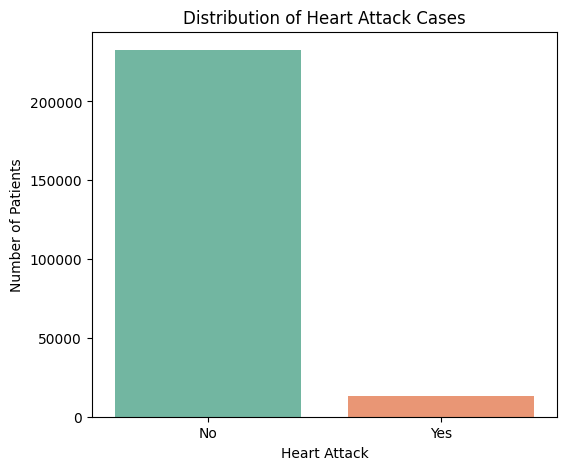

In [8]:


plt.figure(figsize=(6,5))
sns.countplot(data=df, x='HadHeartAttack', palette='Set2')

plt.title('Distribution of Heart Attack Cases')
plt.xlabel('Heart Attack')
plt.ylabel('Number of Patients')

plt.show()

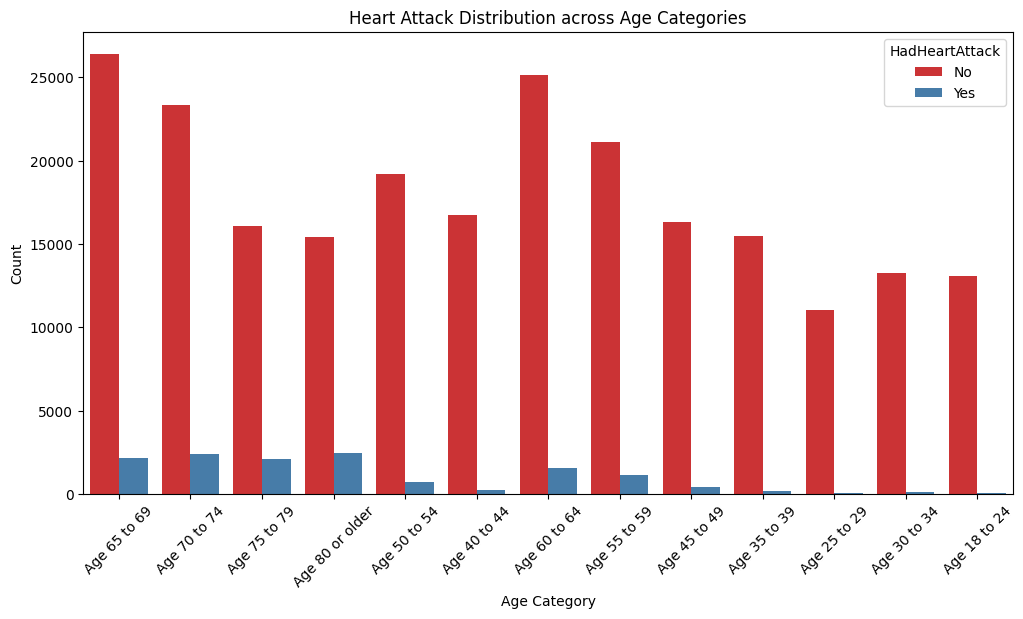

In [9]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x='AgeCategory',
    hue='HadHeartAttack',
    palette='Set1'
)

plt.title('Heart Attack Distribution across Age Categories')
plt.xlabel('Age Category')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

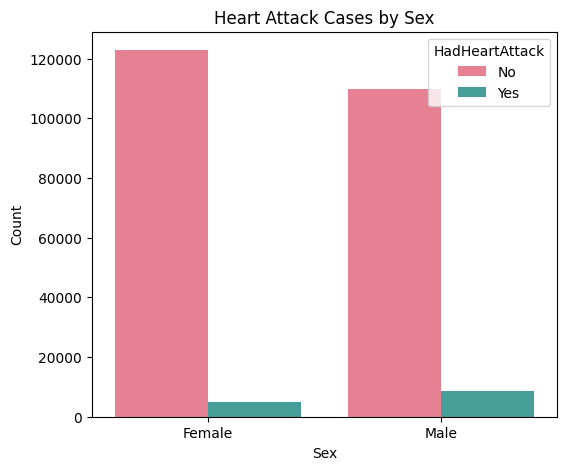

In [10]:
plt.figure(figsize=(6,5))

sns.countplot(
    data=df,
    x='Sex',
    hue='HadHeartAttack',
    palette='husl'
)

plt.title('Heart Attack Cases by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')

plt.show()

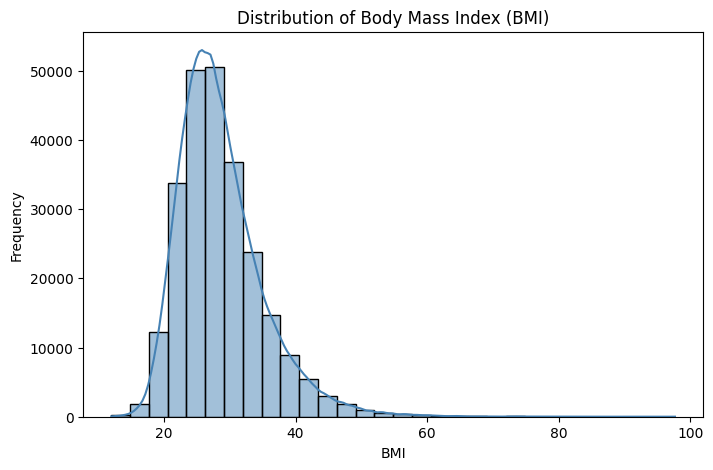

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='BMI',
    bins=30,
    kde=True,
    color='steelblue'
)

plt.title('Distribution of Body Mass Index (BMI)')
plt.xlabel('BMI')
plt.ylabel('Frequency')

plt.show()

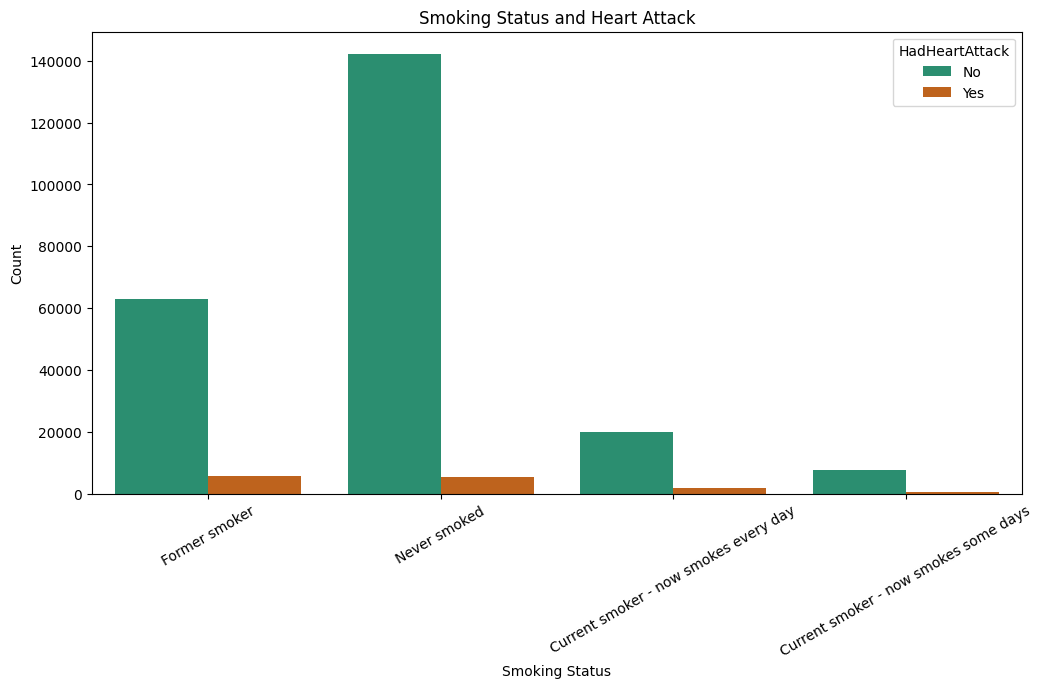

In [12]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x='SmokerStatus',
    hue='HadHeartAttack',
    palette='Dark2'
)

plt.title('Smoking Status and Heart Attack')
plt.xlabel('Smoking Status')
plt.ylabel('Count')

plt.xticks(rotation=30)

plt.show()

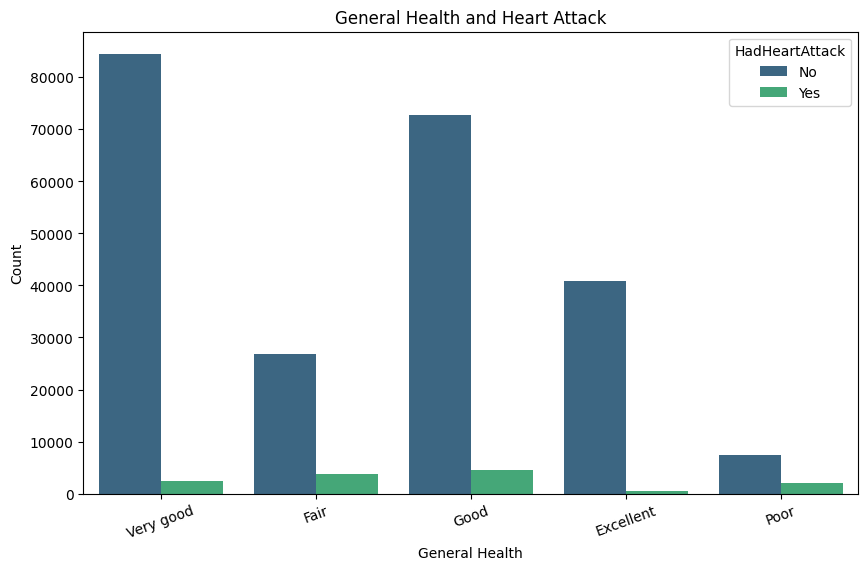

In [13]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x='GeneralHealth',
    hue='HadHeartAttack',
    palette='viridis'
)

plt.title('General Health and Heart Attack')
plt.xlabel('General Health')
plt.ylabel('Count')

plt.xticks(rotation=20)

plt.show()

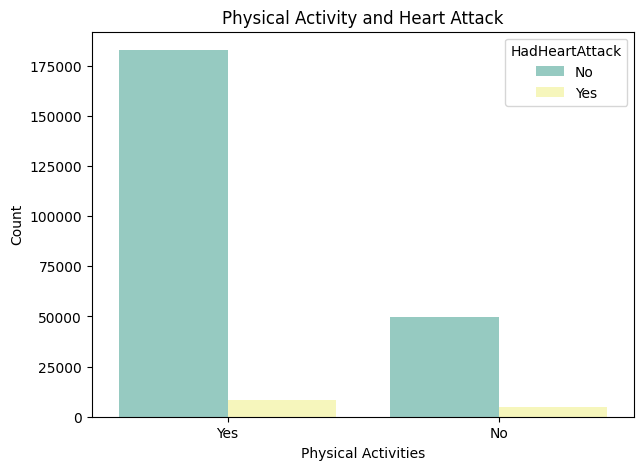

In [14]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='PhysicalActivities',
    hue='HadHeartAttack',
    palette='Set3'
)

plt.title('Physical Activity and Heart Attack')
plt.xlabel('Physical Activities')
plt.ylabel('Count')

plt.show()

In [15]:
from sklearn.preprocessing import LabelEncoder

# Encode all categorical columns
label_encoder = LabelEncoder()

for column in df.select_dtypes(include='object').columns:
    df[column] = label_encoder.fit_transform(df[column])

# Verify data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246022 entries, 0 to 246021
Data columns (total 40 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   State                      246022 non-null  int32  
 1   Sex                        246022 non-null  int32  
 2   GeneralHealth              246022 non-null  int32  
 3   PhysicalHealthDays         246022 non-null  float64
 4   MentalHealthDays           246022 non-null  float64
 5   LastCheckupTime            246022 non-null  int32  
 6   PhysicalActivities         246022 non-null  int32  
 7   SleepHours                 246022 non-null  float64
 8   RemovedTeeth               246022 non-null  int32  
 9   HadHeartAttack             246022 non-null  int32  
 10  HadAngina                  246022 non-null  int32  
 11  HadStroke                  246022 non-null  int32  
 12  HadAsthma                  246022 non-null  int32  
 13  HadSkinCancer              24

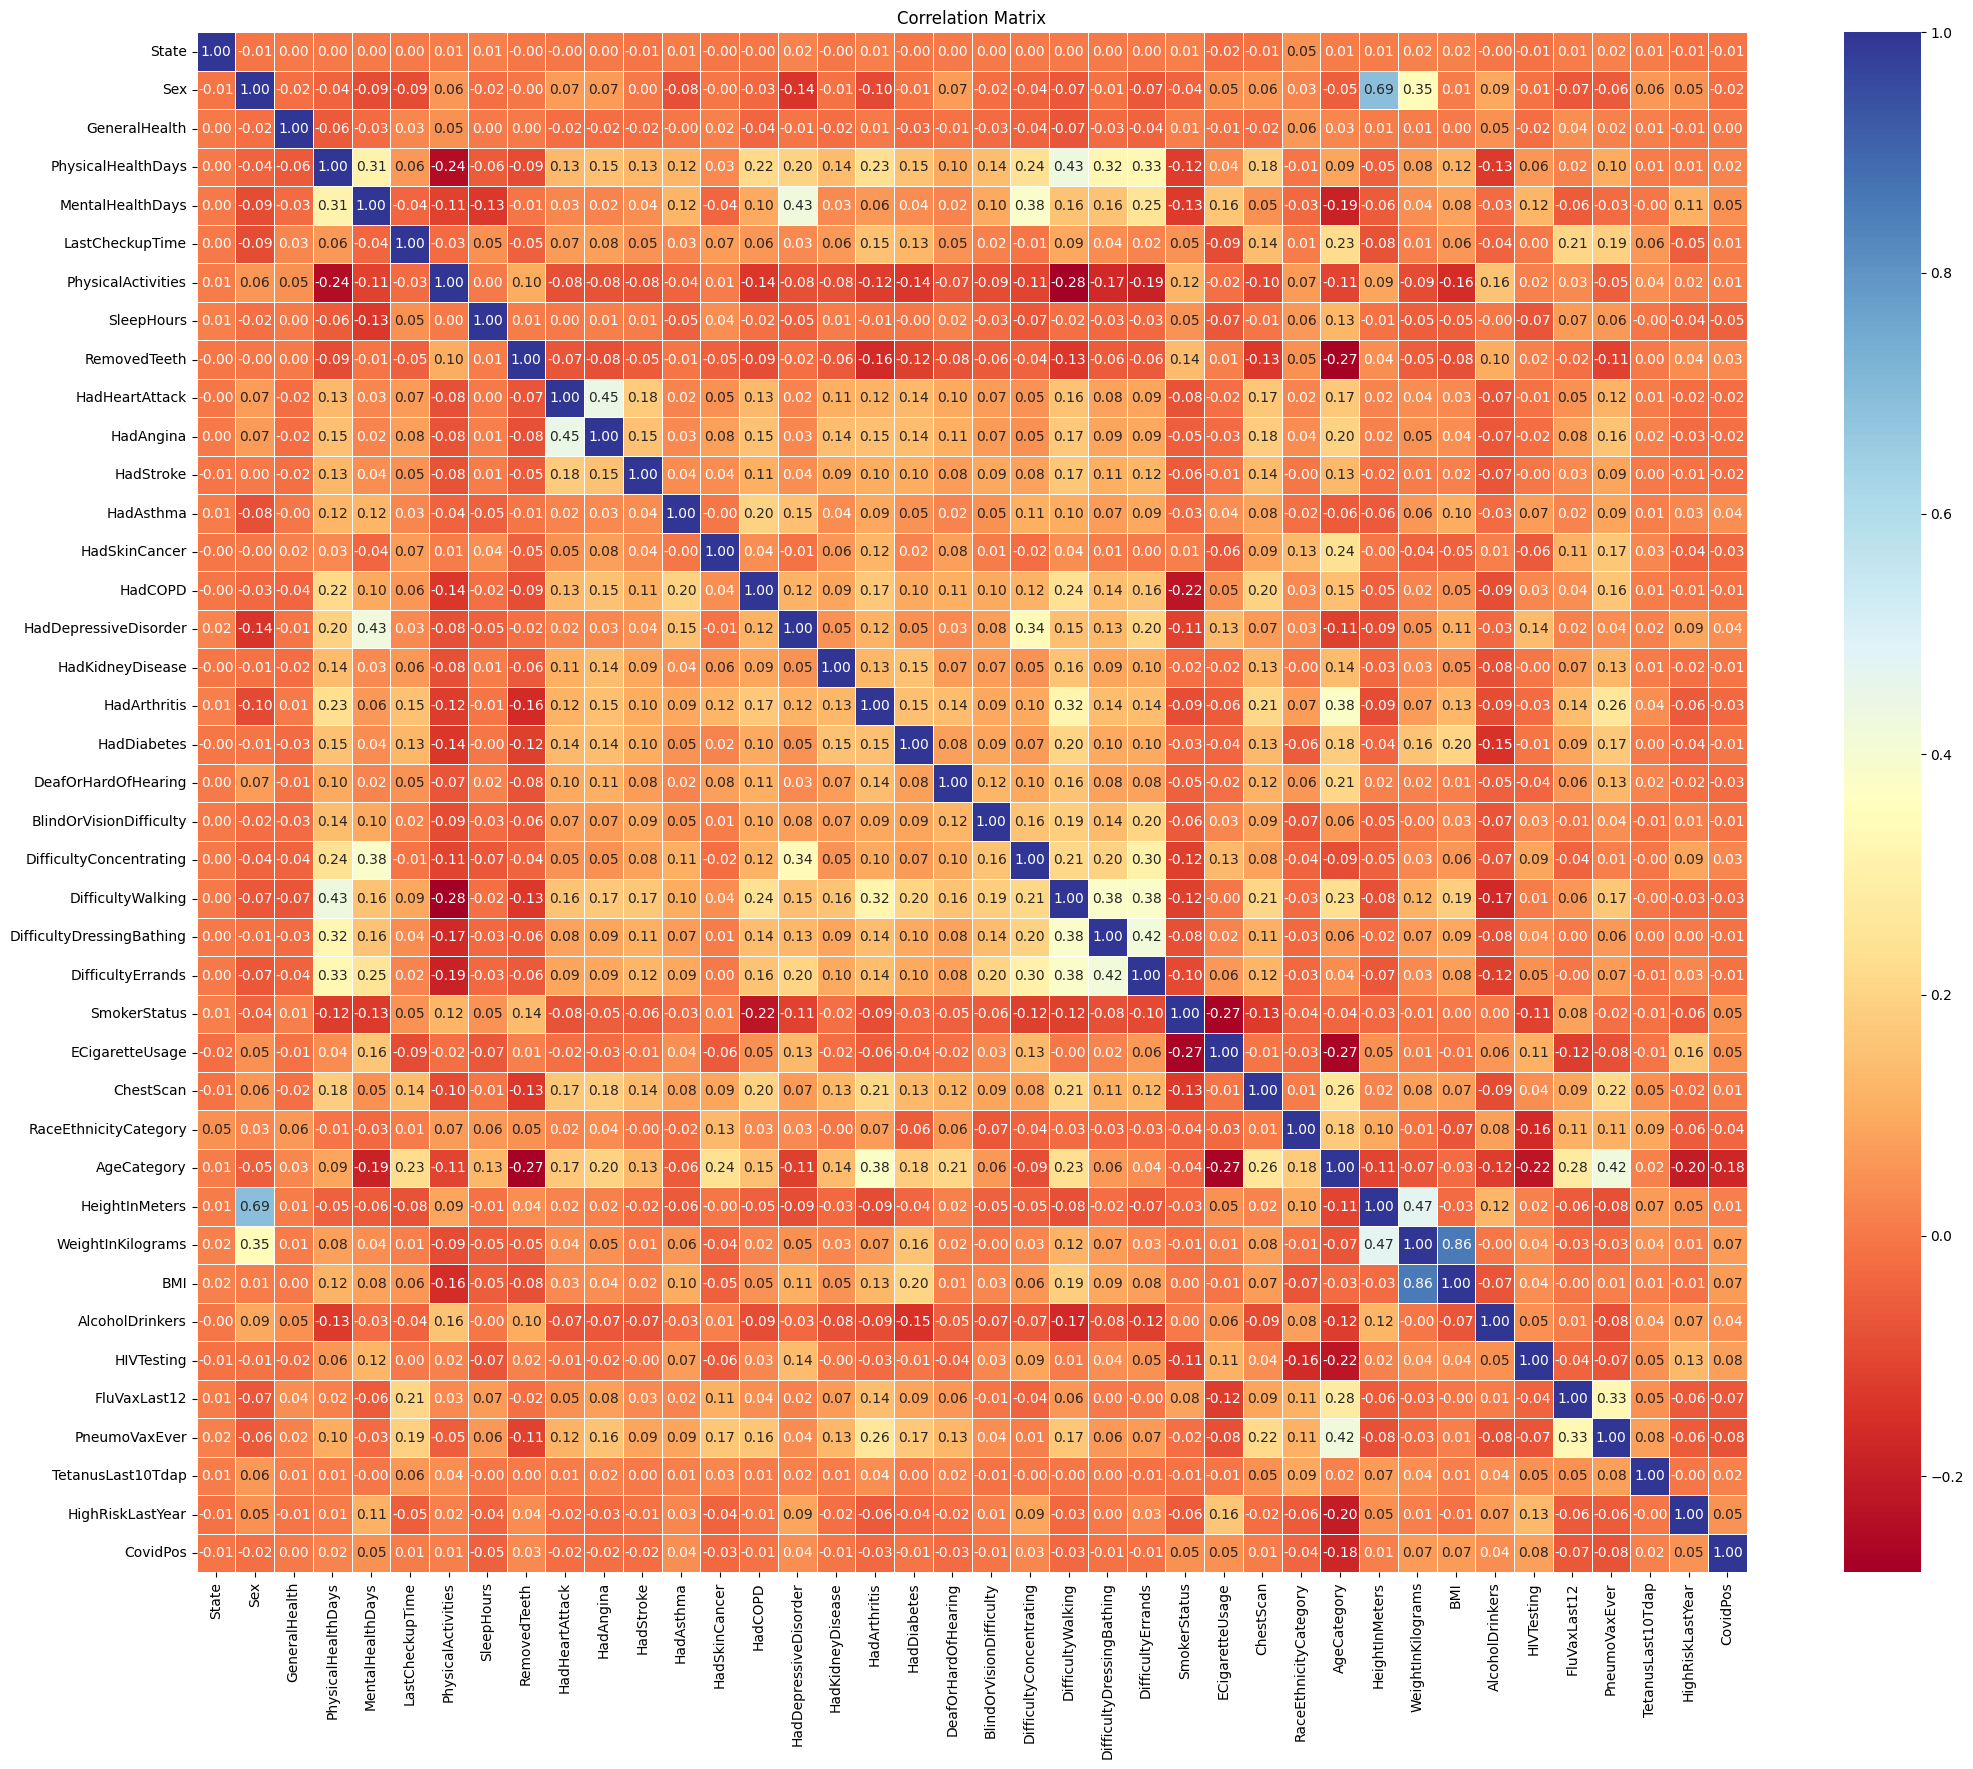

In [16]:
# ---------------------------------------------------------
# Correlation Heatmap
# ---------------------------------------------------------

plt.figure(figsize=(25,20))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt='.2f',
    cmap='RdYlBu',
    linewidths=0.5
)

plt.title('Correlation Matrix')
plt.show()

Model Implementation and Evaluation

In [17]:
X = df.drop('HadHeartAttack', axis=1)
y = df['HadHeartAttack']

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

========== Logistic Regression ==========

Accuracy : 0.9477085662026217
Precision: 0.5491379310344827
Recall   : 0.23706736136955714
F1-Score : 0.3311671432284897

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.99      0.97     46518
           1       0.55      0.24      0.33      2687

    accuracy                           0.95     49205
   macro avg       0.75      0.61      0.65     49205
weighted avg       0.94      0.95      0.94     49205



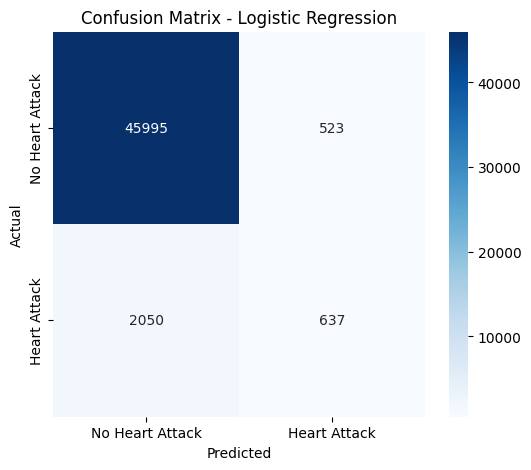

In [20]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("========== Logistic Regression ==========\n")

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1-Score :", f1_score(y_test, y_pred_lr))

print("\nClassification Report\n")
print(classification_report(y_test, y_pred_lr))

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Heart Attack','Heart Attack'],
    yticklabels=['No Heart Attack','Heart Attack']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

========== Decision Tree ==========

Accuracy : 0.9134437557158825
Precision: 0.2498408656906429
Recall   : 0.29214737625604764
F1-Score : 0.26934294047006346

Classification Report

              precision    recall  f1-score   support

           0       0.96      0.95      0.95     46518
           1       0.25      0.29      0.27      2687

    accuracy                           0.91     49205
   macro avg       0.60      0.62      0.61     49205
weighted avg       0.92      0.91      0.92     49205



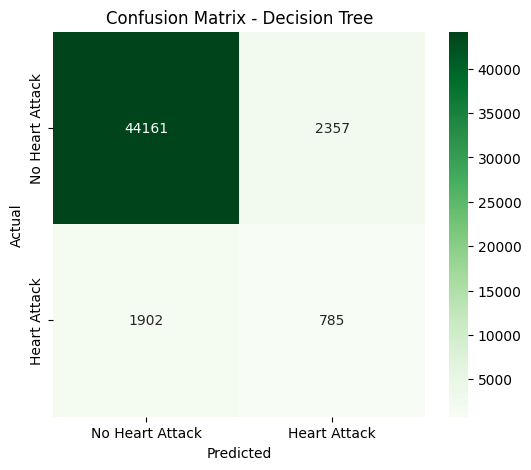

In [21]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("========== Decision Tree ==========\n")

print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall   :", recall_score(y_test, y_pred_dt))
print("F1-Score :", f1_score(y_test, y_pred_dt))

print("\nClassification Report\n")
print(classification_report(y_test, y_pred_dt))

cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Heart Attack','Heart Attack'],
    yticklabels=['No Heart Attack','Heart Attack']
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

========== Random Forest ==========

Accuracy : 0.9482776140636114
Precision: 0.5891959798994975
Recall   : 0.17454410122813546
F1-Score : 0.2693080677576802

Classification Report

              precision    recall  f1-score   support

           0       0.95      0.99      0.97     46518
           1       0.59      0.17      0.27      2687

    accuracy                           0.95     49205
   macro avg       0.77      0.58      0.62     49205
weighted avg       0.93      0.95      0.93     49205



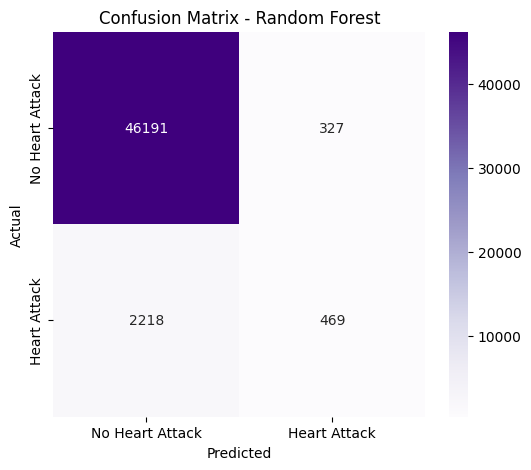

In [22]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("========== Random Forest ==========\n")

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1-Score :", f1_score(y_test, y_pred_rf))

print("\nClassification Report\n")
print(classification_report(y_test, y_pred_rf))

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['No Heart Attack','Heart Attack'],
    yticklabels=['No Heart Attack','Heart Attack']
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [23]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],

    'F1-Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.947709,0.549138,0.237067,0.331167
1,Decision Tree,0.913444,0.249841,0.292147,0.269343
2,Random Forest,0.948278,0.589196,0.174544,0.269308


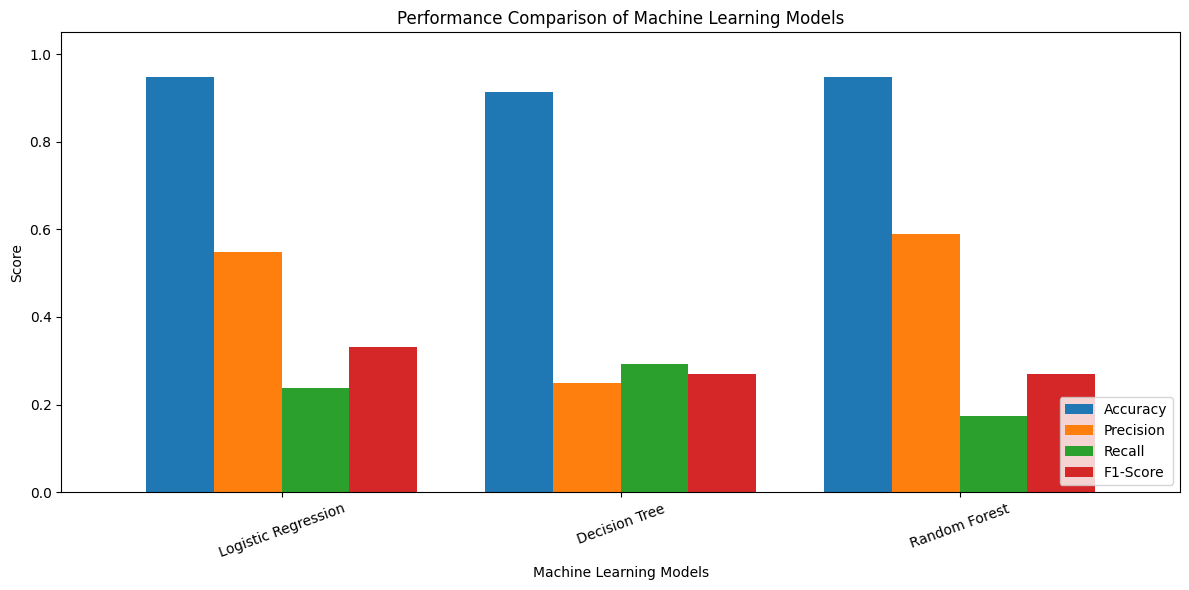

In [24]:


results.set_index('Model').plot(
    kind='bar',
    figsize=(12,6),
    width=0.8
)

plt.title('Performance Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.ylim(0,1.05)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

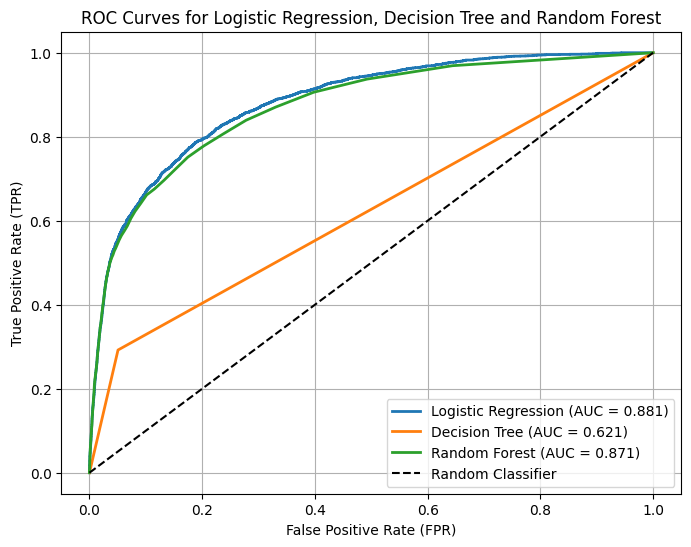

In [25]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predicted probabilities
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
dt_prob = dt.predict_proba(X_test)[:, 1]
rf_prob = rf.predict_proba(X_test)[:, 1]

# ROC Curve and AUC
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
auc_lr = roc_auc_score(y_test, lr_prob)

fpr_dt, tpr_dt, _ = roc_curve(y_test, dt_prob)
auc_dt = roc_auc_score(y_test, dt_prob)

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
auc_rf = roc_auc_score(y_test, rf_prob)

# Plot ROC Curves
plt.figure(figsize=(8,6))

plt.plot(fpr_lr, tpr_lr, linewidth=2,
         label=f'Logistic Regression (AUC = {auc_lr:.3f})')

plt.plot(fpr_dt, tpr_dt, linewidth=2,
         label=f'Decision Tree (AUC = {auc_dt:.3f})')

plt.plot(fpr_rf, tpr_rf, linewidth=2,
         label=f'Random Forest (AUC = {auc_rf:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Classifier')

plt.title('ROC Curves for Logistic Regression, Decision Tree and Random Forest')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()